In [1]:
source('../../../R/preamble.R')

In [2]:
spot_volume = 4 # ul
dil_factor = 1/4 # fold dilution

d = read.tsv('../../../datasets/phage/phage_production/plaque_counts.tsv') %>%

    # Calculate PFUs per microliter of culture
    mutate(
        volume = spot_volume * dil_factor^dilution, # dilutions are zero-indexed in this file
        pfu = count / volume
        )

In [3]:
names = c(
'W1'= 'A00',
'W2'= 'F00',
'A'= 'A06',
'B'= 'A12',
'C'= 'A18',
'D'= 'A24',
'E'= 'F06',
'F'= 'F12',
'G'= 'F18',
'H'= 'F24'
)

d =
d %>% 
    mutate(
        name = names[letter],
        pop = substr(name, 1, 1),
        gen = as.integer(substr(name, 2, 3))
        )

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop and gen.
ℹ Output is grouped by pop.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, gen))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


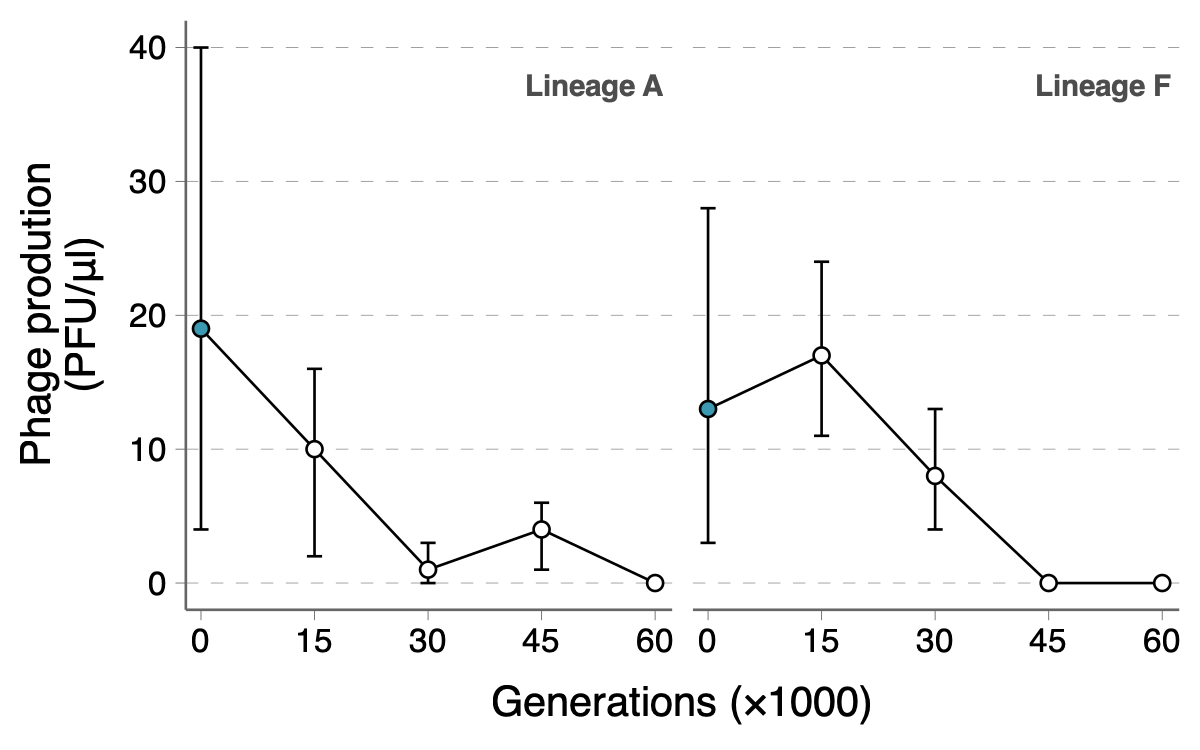

In [4]:
size(2.5, 4)
lwd = 0.3

xmax = 24.5
ymax = 38
letters = tibble(pop=c('A','F'), gen = xmax, pfu_mean = ymax, pfu_min = ymax, pfu_max = ymax)

d %>%
    group_by(pop, gen) %>%
    summarise(
        pfu_mean = mean(pfu), pfu_max = max(pfu), pfu_min = min(pfu)
        ) %>% 

ggplot() + aes(gen * 2.5, 
               y = pfu_mean, ymin = pfu_min, ymax = pfu_max,
               fill = gen == 0, group = T
              ) + nl +

    facet_grid(~pop) +
    theme(
        strip.text=eb,
        panel.grid.major.x=eb
    ) +

    scale_y_continuous(limits = c(0, 40), expand = expansion(mult=0.05)) +
    scale_x_continuous(breaks = seq(0, 60, 15), expand = expansion(add=1)) +
    scale_fill_manual(values = c(w, pal[1])) +

    geom_line(lwd = lwd) +
    geom_errorbar(lwd = lwd, width = 2) +
    geom_point(pch = 21, size = 1.5, stroke = lwd * 1.5) +

    # Lineages
    geom_text(
        data = letters, aes(label=paste('Lineage',pop)),
        size = 2.5, col = 'grey30', fontface = 'bold', hjust = 1, vjust = 1
    ) +

    # Asterisk indicates that the phage is gone from the genome
    #geom_text(data = data.frame(pop = 'A', pfu_mean = 2, gen = 24, pfu_min = 5, pfu_max = 5), label = '*', size = 4) +
        
    labs(x = 'Generations (×1000)', y = 'Phage prodution\n(PFU/μl)')

psave('Plots/PFUs_errorbars')